# Released model review
Author and Kaggle team: **Zihan Xu**. Snapshot: 2026-11-06, core_ep240 v1.

## tl;dr
The accepted three-seed recipe averages 95.3867% raw validation accuracy and 95.7667% with horizontal-flip probability averaging. The fixed deployment seed42 reaches 95.78% with flip inference. Each checkpoint has 2,436,346 trainable parameters. The reported Kaggle score for seed42/raw is 85.00%; flip policies have no reported score.

## Context & Methods
This notebook checks saved predictions, checkpoint parameter counts, logs and CSV hashes. It does not retrain or query hidden labels. Training was from scratch on 40,000 course images; checkpoint selection used a fixed stratified 5,000-image validation set. Repeated seeds share those same images.

### Key Assumptions
The 86-run accepted study is the selection scope. Seed42 remains the deployment seed instead of picking a favorable seed after evaluation. Flip inference averages two softmax distributions from one checkpoint. Validation improvements do not establish a hidden-test improvement.

## Data
Inputs are the release's `evidence/`, `models/`, `versions.json` and `submissions/`. All computations below use files distributed with this repository.

In [1]:
from pathlib import Path
import sys, json, csv, hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

TASK = Path.cwd()
if not (TASK / 'versions.json').exists():
    TASK = TASK / 'tasks/2026-11-06_core_ep240_v1'
assert (TASK / 'versions.json').exists()
ROOT = TASK.parents[1]
sys.path.insert(0, str(ROOT))
from experiments.research_sweep.combinations.methods import build
versions = json.loads((TASK / 'versions.json').read_text())
summary = pd.read_csv(TASK / 'evidence/study_summary.csv')
assert (summary['n'] == summary['planned_n']).all()
assert summary.loc[summary.mean_accuracy_percent.idxmax(), 'configuration'] == 'core_ep240'
print('Accepted comparison scope:', len(summary), 'configurations;', int(summary.n.sum()), 'completed runs')
print('Python', sys.version.split()[0], '| torch', torch.__version__)


Accepted comparison scope: 22 configurations; 86 completed runs
Python 3.13.5 | torch 2.11.0+cu128


## Results
### 1. Recompute validation accuracy and parameter count

In [2]:
records = []
for seed in [42, 43, 44]:
    checkpoint = torch.load(TASK / f'models/seed{seed}.pt', map_location='cpu', weights_only=True)
    model = build(checkpoint['recipe'])
    model.load_state_dict(checkpoint['model_state'], strict=True)
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert parameters == 2436346 and parameters <= 5000000
    values = np.load(TASK / f'evidence/seed{seed}/validation_probabilities.npz')
    assert len(values['ids']) == len(np.unique(values['ids'])) == 5000
    for policy in ['raw', 'flip']:
        correct = int((values[policy].argmax(1) == values['labels']).sum())
        records.append(dict(seed=seed, policy=policy, correct=correct, n=5000,
                            validation_percent=correct/50, parameters=parameters))
results = pd.DataFrame(records)
display(results)
display(results.groupby('policy').validation_percent.agg(['mean', 'std']))
print('Final model trainable parameters:', parameters)
print('Reported Kaggle public score (seed42/raw): 85.00%; user-reported, not computed from hidden labels.')
print('Flip Kaggle score: unavailable. Final private-test accuracy: unavailable.')


,seed,policy,correct,n,validation_percent,parameters
0,42,raw,4763,5000,95.26,2436346
1,42,flip,4789,5000,95.78,2436346
2,43,raw,4766,5000,95.32,2436346
3,43,flip,4784,5000,95.68,2436346
4,44,raw,4779,5000,95.58,2436346
5,44,flip,4792,5000,95.84,2436346


,mean,std
policy,,
flip,95.766667,0.080829
raw,95.386667,0.170098


Final model trainable parameters: 2436346
Reported Kaggle public score (seed42/raw): 85.00%; user-reported, not computed from hidden labels.
Flip Kaggle score: unavailable. Final private-test accuracy: unavailable.


### 2. Verify the four submission versions

In [3]:
for version in versions:
    path = TASK / 'submissions' / version['version'] / 'submission.csv'
    data = pd.read_csv(path)
    assert data.columns.tolist() == ['id', 'label']
    assert len(data) == data.id.nunique() == 2000
    assert data.id.tolist() == list(range(2000))
    assert pd.api.types.is_integer_dtype(data.label) and data.label.between(0, 9).all()
    assert hashlib.sha256(path.read_bytes()).hexdigest() == version['sha256']
display(pd.DataFrame(versions)[['version', 'policy', 'seed', 'validation_percent', 'kaggle_score']])
print('All four CSVs passed shape, sample-order, class-range and digest checks.')


,version,policy,seed,validation_percent,kaggle_score
0,01_recommended_seed42_flip,flip,42,95.78,NaN
1,02_reference_seed42_raw,raw,42,95.26,0.85
2,03_alternative_seed43_flip,flip,43,95.68,NaN
3,04_alternative_seed44_flip,flip,44,95.84,NaN


All four CSVs passed shape, sample-order, class-range and digest checks.


### 3. Training progression
Raw validation accuracy at each epoch; three runs evaluated on the same 5,000 images.

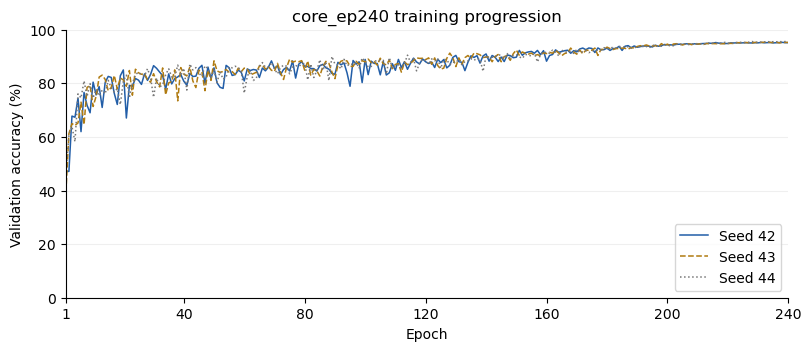

In [4]:
(TASK / 'figures').mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
for seed, color, style in [(42, '#225EA8', '-'), (43, '#B07B11', '--'), (44, '#777777', ':')]:
    history = pd.read_csv(TASK / f'evidence/seed{seed}/history.csv')
    assert history.epoch.tolist() == list(range(1, 241))
    ax.plot(history.epoch, history.validation_accuracy*100, color=color, ls=style, lw=1.1, label=f'Seed {seed}')
ax.set(xlabel='Epoch', ylabel='Validation accuracy (%)', title='core_ep240 training progression', xlim=(1,240), ylim=(0,100))
ax.set_xticks([1, 40, 80, 120, 160, 200, 240]); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=.2)
fig.savefig(TASK / 'figures/training.png', dpi=180)
display(fig); plt.close(fig)


The training recipe runs the full 240 epochs; the earlier epoch wins a checkpoint tie. The original training histories remain unchanged.

### 4. Inference comparison
Focused accuracy scale. Connected points show the same checkpoint before and after flip averaging; they are not confidence intervals.

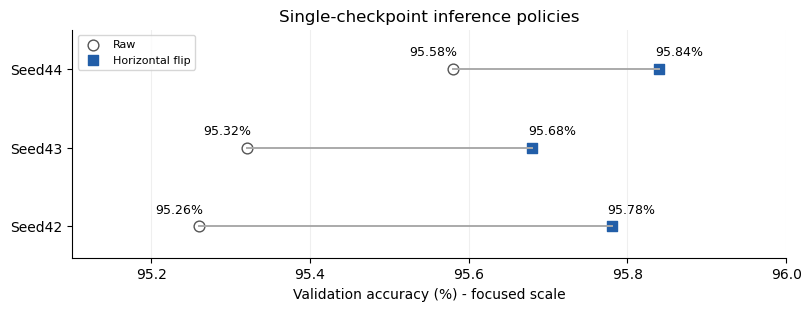

In [5]:
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
for y, seed in enumerate([42,43,44]):
    raw = float(results[(results.seed == seed) & (results.policy == 'raw')].validation_percent.iloc[0])
    flip = float(results[(results.seed == seed) & (results.policy == 'flip')].validation_percent.iloc[0])
    ax.plot([raw,flip], [y,y], color='#AAAAAA', lw=1.4)
    ax.scatter(raw, y, marker='o', facecolors='white', edgecolors='#555555', s=60, label='Raw' if y==0 else None)
    ax.scatter(flip, y, marker='s', color='#225EA8', s=45, label='Horizontal flip' if y==0 else None)
    ax.text(raw-.025, y+.17, f'{raw:.2f}%', ha='center', fontsize=9)
    ax.text(flip+.025, y+.17, f'{flip:.2f}%', ha='center', fontsize=9)
ax.set(xlabel='Validation accuracy (%) - focused scale', title='Single-checkpoint inference policies', xlim=(95.1,96.0), ylim=(-.4,2.5))
ax.set_yticks([0,1,2], ['Seed42','Seed43','Seed44']); ax.legend(loc='upper left', fontsize=8); ax.grid(axis='x', alpha=.2)
fig.savefig(TASK / 'figures/inference.png', dpi=180)
display(fig); plt.close(fig)


## Takeaways
The three-seed mean improvement for flip averaging is +0.38 percentage points, with no additional trainable parameters and approximately twice as many forward passes. All three seeds improve on this validation set. The previous paired-seed t interval is [0.0542, 0.7058] percentage points; this is exploratory evidence on a repeatedly used split, not an independent-data guarantee.

The recommended CSV uses fixed seed42. Seed43 and seed44 are alternatives, not evidence for selecting a favorable deployment seed. The local-to-Kaggle gap remains unexplained; the new policies require official scoring. No held-out competition labels are available here.

References: [ResNet](https://arxiv.org/abs/1512.03385), [BlurPool](https://arxiv.org/abs/1904.11486), [Cutout](https://arxiv.org/abs/1708.04552).